# Visualizing Data Veracity Challenges in Multi-Label Classification

In this assignment, we have to examine any data quality issues within the provided <i>Yeast Dataset</i>. Some of these issues include:
1. Noisy/Ambiguous Labels: Genes whose functions span multiple categories or are misclassified.
2. Outliers: Experiments with highly unusual gene expression profiles.
3. Hard-to-Learn Samples: Data points lying in regions where functional categories are thoroughly
mixed.

These issues can persist even after standardization of the dataset.

## Imports

In [ ]:
from scipy.io import arff
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import NullFormatter
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE, Isomap

## PART A : Data Preprocessing

We convert the data format from ARFF to CSV (using Pandas)

In [ ]:
data = arff.loadarff('data/yeast/yeast.arff')
df = pd.DataFrame(data[0])
for i in range(1, 15):
    df[f'Class{i}'] = pd.to_numeric(df[f'Class{i}'])

Preliminary Observations:
1. Classes are one-hot encoded
2. Total number of features is 103
3. Total number of classes is 14

In [ ]:
x = df[[f'Att{i}' for i in range(1, 104)]]  # 103 features
y = df[[f'Class{i}' for i in range(1, 15)]]  # 14 classes

In [ ]:
df.describe()

In [ ]:
y.describe()

Class 12 and Class 13 are the most frequent classes

In [ ]:
multi_label_frequency = dict()
for i in y.columns:
    for j in y.columns:
        if i != j and (j, i) not in multi_label_frequency:
            l = np.sum(y[[i, j]], axis=1)
            multi_label_frequency[(i, j)] = len(l[l==2])
multi_label_frequency = dict(sorted(
    multi_label_frequency.items(),
    key=lambda kv: (kv[1], kv[0]),
    reverse=True
))

Most Frequent Multi-label combination is Class12 & Class13

In [ ]:
label1, label2, label31, label32, label4 = 'Class12', 'Class13', 'Class12', 'Class13', 'Other'
df.loc[y[label1] == 1, 'Group'] = 1
df.loc[y[label2] == 1, 'Group'] = 2
df.loc[np.sum(y[[label31, label32]], axis=1) == 2, 'Group'] = 3
df.loc[np.sum(y[[label1, label2]], axis=1) == 0, 'Group'] = 0

In [ ]:
df

In [ ]:
y = df['Group']

We need to standardize the Feature matrix as the following data transformation techniques (namely t-SNE and Isomap) involve a metric distance for their computations. Metric distance are not scale-invariant as they utilise the actual point coordinates. This would result in similar points being far apart due to a large scale of a particular feature.

In [ ]:
x_std = StandardScaler().fit_transform(x)

In [ ]:
pd.DataFrame(x_std)

In [ ]:
def display_data(x):
    plt.scatter(x[y==1, 0], x[y==1, 1], c='r')
    plt.scatter(x[y==2, 0], x[y==2, 1], c='b')
    plt.scatter(x[y==3, 0], x[y==3, 1], c='y')
    plt.scatter(x[y==0, 0], x[y==0, 1], c='g')
    plt.show()

In [ ]:
display_data(x_std)

In [ ]:
x_pca = PCA(n_components=0.95).fit_transform(x_std)

In [ ]:
x_pca.shape

In [ ]:
display_data(x_pca)

In [ ]:
tsne = TSNE(n_components=2, init="random", perplexity=30)
x_tsne = tsne.fit_transform(x_pca)
display_data(x_tsne)

## PART B

It is recommended on the Scikit-learn website to perform PCA on the data to reduce the number of features of the data

### With Pre-PCA

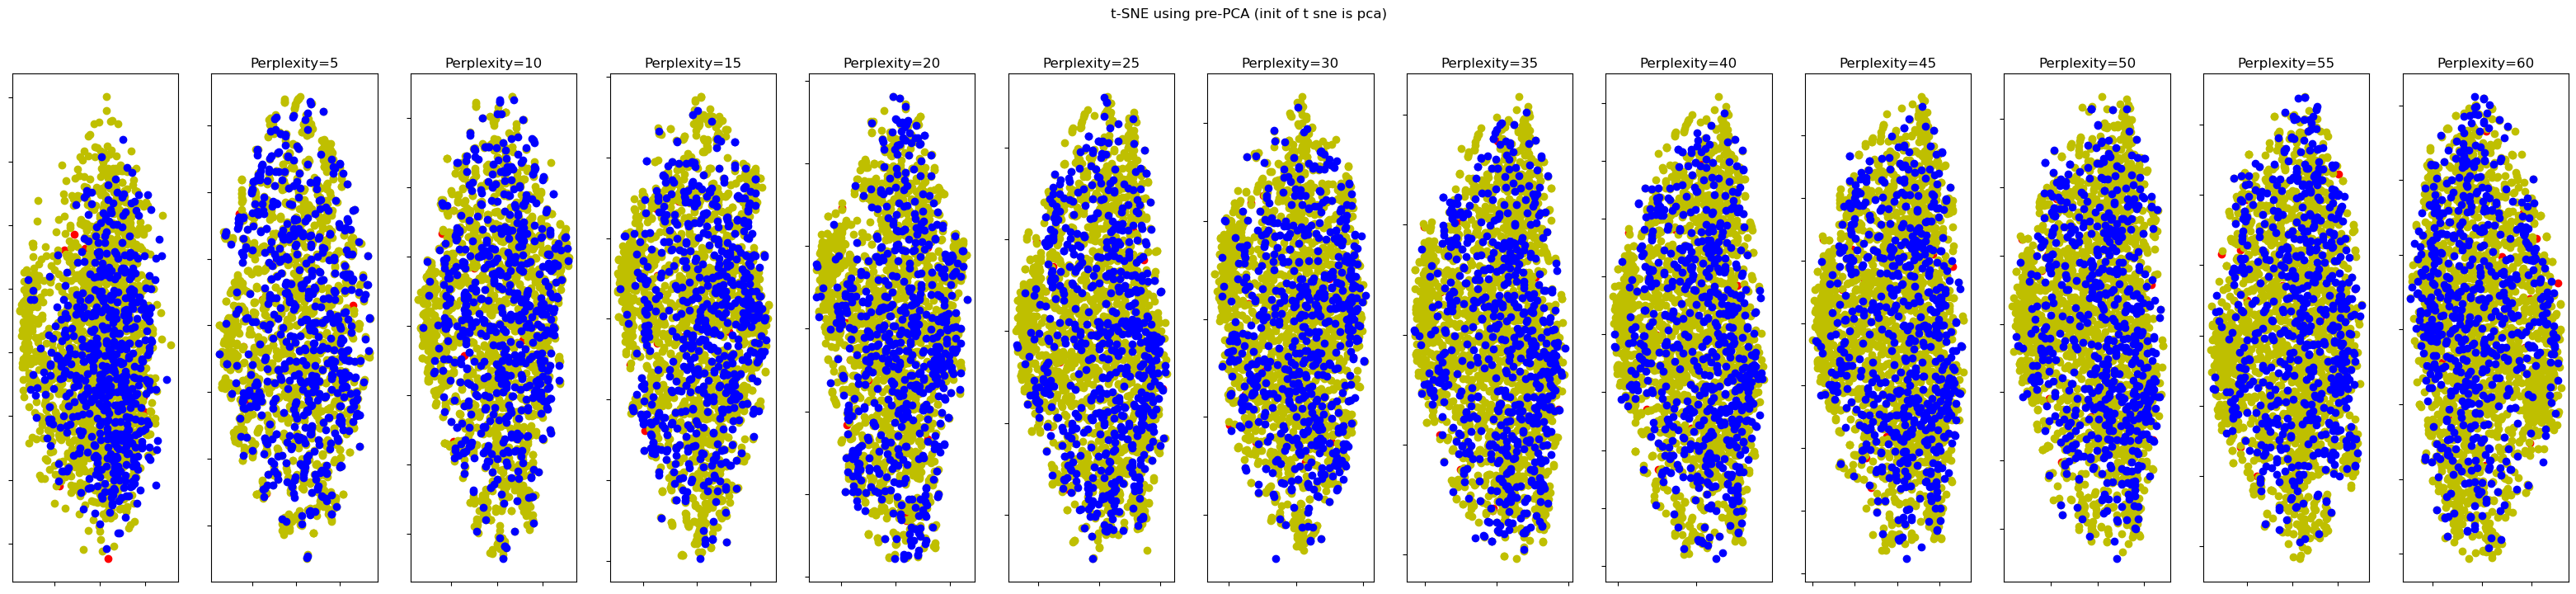

In [30]:
pca = PCA(n_components=0.95, random_state=0)
x_pca = pca.fit_transform(x_std)
perplexities = list(range(5, 61, 5))
(fig, subplots) = plt.subplots(1, len(perplexities) + 1, figsize=(40, 8))
ax = subplots[0]
ax.scatter(x_pca[y==1, 0], x_pca[y==1, 1], c="r")
ax.scatter(x_pca[y==2, 0], x_pca[y==2, 1], c="g")
ax.scatter(x_pca[y==3, 0], x_pca[y==3, 1], c="y")
ax.scatter(x_pca[y==0, 0], x_pca[y==0, 1], c="b")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
plt.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[i + 1]

    tsne = TSNE(n_components=2, init="pca", perplexity=perplexity, random_state=0)
    Y = tsne.fit_transform(x_pca)
    ax.set_title("Perplexity=%d" % perplexity)
    ax.scatter(Y[y==1, 0], Y[y==1, 1], c="r")
    ax.scatter(Y[y==2, 0], Y[y==2, 1], c="g")
    ax.scatter(Y[y==3, 0], Y[y==3, 1], c="y")
    ax.scatter(Y[y==0, 0], Y[y==0, 1], c="b")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")
fig.suptitle("t-SNE using pre-PCA (init of t sne is pca)")
plt.savefig("images/tsne_pca.png")
plt.show()

In [ ]:
perplexities = list(range(5, 61, 5))
(fig, subplots) = plt.subplots(1, len(perplexities) + 1, figsize=(40, 8))
ax = subplots[0]
ax.scatter(x_std[y==1, 0], x_std[y==1, 1], c="r")
ax.scatter(x_std[y==2, 0], x_std[y==2, 1], c="g")
ax.scatter(x_std[y==3, 0], x_std[y==3, 1], c="y")
ax.scatter(x_std[y==0, 0], x_std[y==0, 1], c="b")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
plt.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[i + 1]

    tsne = TSNE(
        n_components=2,
        init="pca",
        perplexity=perplexity,
        random_state=0
    )
    Y = tsne.fit_transform(x_std)
    ax.set_title("Perplexity=%d" % perplexity)
    ax.scatter(Y[y==1, 0], Y[y==1, 1], c="r")
    ax.scatter(Y[y==2, 0], Y[y==2, 1], c="g")
    ax.scatter(Y[y==3, 0], Y[y==3, 1], c="y")
    ax.scatter(Y[y==0, 0], Y[y==0, 1], c="b")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")
plt.title("t-SNE with init of PCA")
plt.show()

### Without Pre-PCA

In [ ]:
perplexities = list(range(5, 61, 5))
(fig, subplots) = plt.subplots(1, len(perplexities) + 1, figsize=(40, 8))
ax = subplots[0]
ax.scatter(x_std[y==1, 0], x_std[y==1, 1], c="r")
ax.scatter(x_std[y==2, 0], x_std[y==2, 1], c="g")
ax.scatter(x_std[y==3, 0], x_std[y==3, 1], c="y")
ax.scatter(x_std[y==0, 0], x_std[y==0, 1], c="b")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
plt.axis("tight")

for i, perplexity in enumerate(perplexities):
    ax = subplots[i + 1]

    tsne = TSNE(
        n_components=2,
        init="random",
        perplexity=perplexity,
        random_state=0
    )
    Y = tsne.fit_transform(x_std)
    ax.set_title("Perplexity=%d" % perplexity)
    ax.scatter(Y[y==1, 0], Y[y==1, 1], c="r")
    ax.scatter(Y[y==2, 0], Y[y==2, 1], c="g")
    ax.scatter(Y[y==3, 0], Y[y==3, 1], c="y")
    ax.scatter(Y[y==0, 0], Y[y==0, 1], c="b")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")
fig.suptitle("t-SNE with init of random")
plt.show()

### Veracity Explanation

## Isomap

KeyboardInterrupt: 

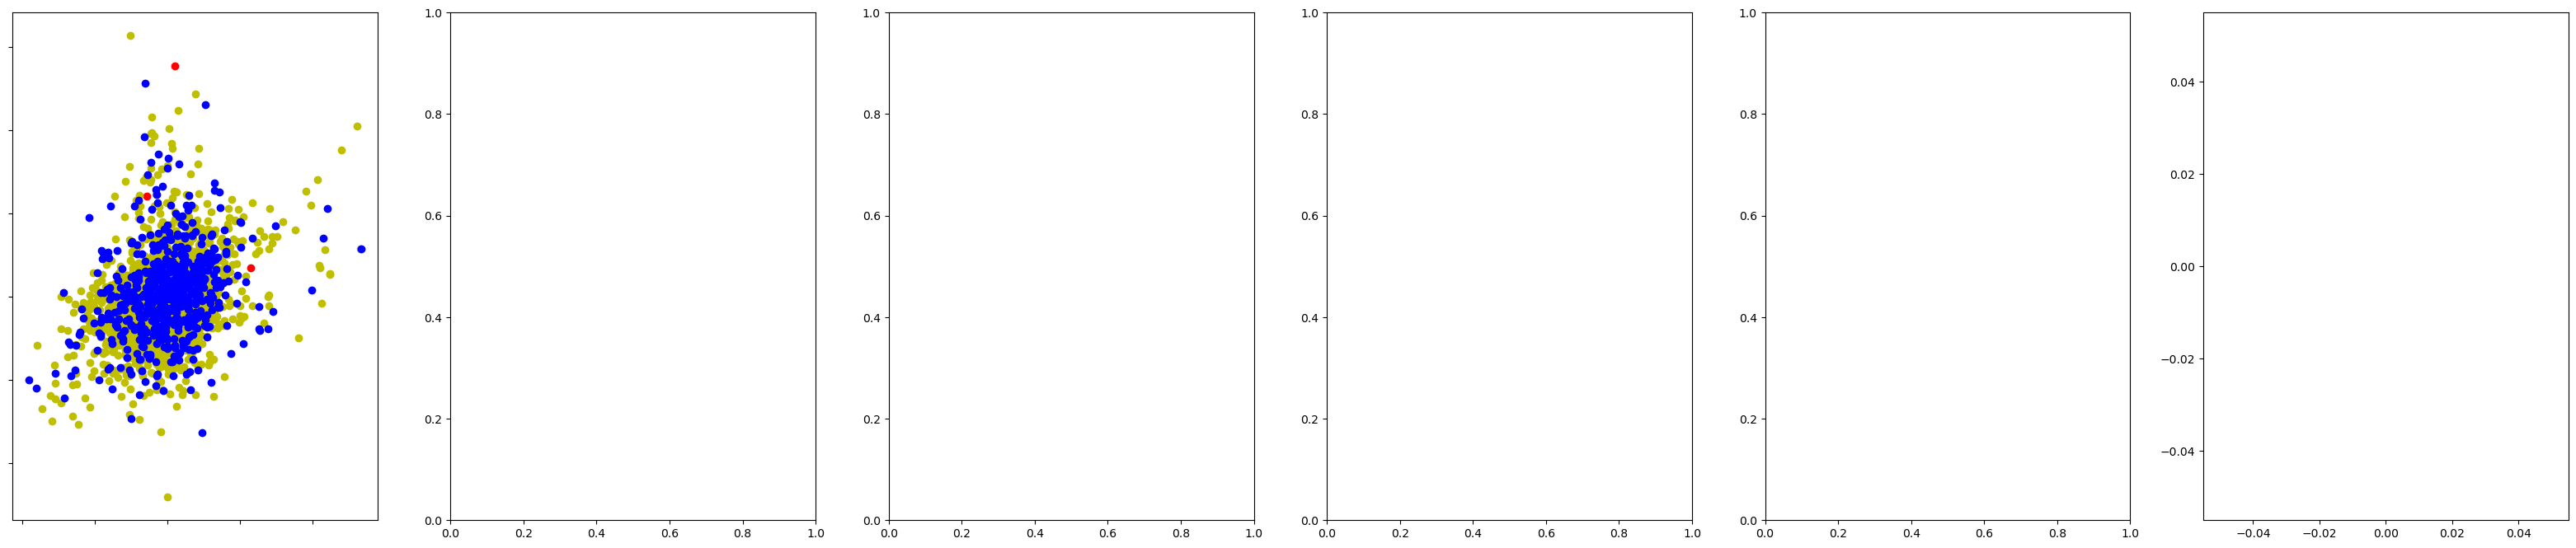

In [41]:
nns = range(100, 150, 10)
(fig, subplots) = plt.subplots(1, len(nns) + 1, figsize=(40, 8))
ax = subplots[0]
ax.scatter(x_std[y==1, 0], x_std[y==1, 1], c="r")
ax.scatter(x_std[y==2, 0], x_std[y==2, 1], c="g")
ax.scatter(x_std[y==3, 0], x_std[y==3, 1], c="y")
ax.scatter(x_std[y==0, 0], x_std[y==0, 1], c="b")
ax.xaxis.set_major_formatter(NullFormatter())
ax.yaxis.set_major_formatter(NullFormatter())
plt.axis("tight")

for i, nn in enumerate(nns):
    ax = subplots[i + 1]
    x_iso = Isomap(n_components = 2, n_neighbors = nn).fit_transform(x_std)
    ax.set_title("# Neighbors =%d" % nn)
    ax.scatter(x_iso[y==1, 0], x_iso[y==1, 1], c="r")
    ax.scatter(x_iso[y==2, 0], x_iso[y==2, 1], c="g")
    ax.scatter(x_iso[y==3, 0], x_iso[y==3, 1], c="y")
    ax.scatter(x_iso[y==0, 0], x_iso[y==0, 1], c="b")
    ax.xaxis.set_major_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(NullFormatter())
    ax.axis("tight")
plt.title("Isomap")
plt.show()

#### Difference between Isomap vs t-SNE

| Isomap | t-SNE|
| :---- | :---|
| Preserves Global distance | Preserves Local distance |
| Deterministic using Graph + MDS | Matching Probabilistic distributions |

1. t-SNE aims to preserve the local relationships between data points. by constructing a probability distribution of the high dimension data wrt similarity and defining a similar distribution on the low dimension using distances of the points. To avoid the curse of dimensionality, it relies on probabilistic distributions.
2. Isomap forms a graph consisting the points as nodes and the edges between K nearest neighbors. The edge length is defined using euclidean distance. 


#### Data Manifold

A manifold is a surface, more specifically a low-dimensional subspace in a higher-dimensional space which is not necessarily linear. We hypothesize that our high-dimensional datasets actually lie on a manifold in their dimension, which enables us to reduce the number of features required. The complexity of a manifold is associated with its dimensionality and the distribution of the data in that manifold. This increases the difficulty of classification tasks as they need to handle larger dimensions and more complex and non-linear relationships between data